# 10 · Redis 主从、哨兵、分片、内存回收与缓存（Redis面试篇）


## 资料来源与学习路线

依据百度网盘 `我的资源/day10-Redis面试篇/PPT/Redis面试篇.pptx` 整理。原 PPT 与网盘预览均为 **69 页，无隐藏页**；4 张课件原图随 Notebook 内嵌，可离线阅读。

| 课件范围 | 本篇知识 |
| --- | --- |
| 第 5—14 页 | 主从读写分离、全量/部分同步、复制优化 |
| 第 16—22 页 | Sentinel 监控、故障判定、选主、故障切换 |
| 第 25—28 页 | Redis Cluster、16384 个槽、CRC16、hash tag |
| 第 31—39 页 | redisObject、编码、跳表、SortedSet |
| 第 42—49 页 | TTL、过期清理、淘汰策略、LRU/LFU |
| 第 52—58 页 | 缓存更新模式、Cache Aside、一致性 |
| 第 60—69 页 | 穿透、布隆过滤、雪崩、击穿 |

配套 `资料/docker-compose.yaml` 与 `资料/sentinel.conf` 已逐项读取。Compose 使用未固定 tag 的 `image: redis`，**无法据此确认课程运行版本**；`redis.tar` 未安装或执行。第 22 页引用的搭建讲义正文未取得，配置示例来自实际配套文件与明确标注的补充。

课件混合了历史编码与 Redis 7.0 的变化。正文保留课程主线，标为“补充/校正”的内容用于解释版本差异和工程边界；LFU、主动过期的实现细节以 **Redis 7.0.15 源码**作说明基线，不代表已确认课程部署为该版本。当前官方文档可能包含更晚版本的新功能。

学习顺序：**选架构 → 理解复制与故障切换 → 理解分片 → 理解对象与内存 → 处理缓存一致性与流量冲击**。本篇未启动 Redis、Docker、Sentinel 或业务服务；命令、配置和结果均为学习示例或验证方法。


## 1. 主从、哨兵和分片分别解决什么

一个 Redis 实例既受单机内存限制，也受单节点处理能力限制；故障时还会中断访问。三个方案解决的问题不同。（课件第 5、16、25 页）

| 方案 | 数据组织 | 解决的问题 | 仍需判断的边界 |
| --- | --- | --- | --- |
| 主从复制 | 一个主节点，副本保存同一份数据 | 数据副本、读取扩展 | 主节点写能力与容量未分片；主故障不自动选主 |
| Sentinel + 主从 | 主从保存数据，独立哨兵监控 | 自动故障切换、发现当前主节点 | 仍是一组数据；客户端要支持 Sentinel |
| Redis Cluster | 多个主节点各保存一部分数据，各自可带副本 | 数据容量、分散写流量、分片高可用 | 单个热点 key 仍落在一个槽，存在跨槽限制 |

`master` 是主节点，`replica` 是副本；课件的 `slave` 为旧称。读写分离通常将写入交给主节点，将允许延迟的查询交给副本。业务要求“刚写完立即读到最新值”时，应把关键读路由到主节点，不能只因为有副本就全部读副本。


## 2. 配套 Compose 启动了什么

搭建前先看配置实际表达了什么，避免把“三个 Redis 进程”误认为“已有主从/分片集群”。配套文件原文如下：

```yaml
version: "3.2"

services:
  r1:
    image: redis
    container_name: r1
    network_mode: "host"
    entrypoint: ["redis-server", "--port", "7001"]
  r2:
    image: redis
    container_name: r2
    network_mode: "host"
    entrypoint: ["redis-server", "--port", "7002"]
  r3:
    image: redis
    container_name: r3
    network_mode: "host"
    entrypoint: ["redis-server", "--port", "7003"]
```

它只指定 **7001、7002、7003 三个独立实例**，未设置 `replicaof`、`cluster-enabled`，也未启动 Sentinel。课件的 `192.168.150.101` 是示例机器地址，应换成参与方都可达的地址。

补充：`network_mode: "host"` 使用宿主机网络，是课程环境选择；不能据此认定在 Windows 的 Docker 环境直接可用。复现时应先确认宿主机、Docker 网络支持与端口占用，固定 Redis 镜像版本，并为各实例准备独立的配置与数据目录。


## 3. 配置主从与验证读写路由

副本必须明确“复制谁”，主从关系不会由端口编号自动形成。沿用课程地址，以下命令将 7002、7003 设为 7001 的副本。（课件第 5 页；补充配置示例）

```bash
redis-cli -h 192.168.150.101 -p 7002 REPLICAOF 192.168.150.101 7001
redis-cli -h 192.168.150.101 -p 7003 REPLICAOF 192.168.150.101 7001
redis-cli -h 192.168.150.101 -p 7001 INFO replication
redis-cli -h 192.168.150.101 -p 7002 INFO replication
```

`REPLICAOF` 是当前名称，`SLAVEOF` 是兼容的旧名称。运行时命令与重启后配置要区分：长期配置通常在副本的 `redis.conf` 中设置 `replicaof 192.168.150.101 7001`。

主节点的 `INFO replication` 应显示 `role:master` 与连接的副本；副本应显示 `role:slave`、主节点地址和 `master_link_status:up`。字段中的 `slave` 仍可能保留旧名称。

> 补充/校正：Redis 默认**异步复制**。主节点成功响应写请求，不意味着所有副本已处理该写入；课件的“实时同步”应理解为持续传播复制流。读副本可能读到旧值，复制也不能代替持久化与备份。


## 4. 全量同步：快照为什么还要接后续写入

新副本没有可用的复制历史，需要先拿到完整数据。全量同步通常用 RDB 快照建立共同起点，再用复制流追上快照期间的变化。（课件第 7—10、14 页）

```text
副本连接主节点，发送 PSYNC 信息
        ↓ 无法部分同步
主节点返回 FULLRESYNC（复制 ID、起始 offset）
        ↓
生成并发送 RDB 快照；同时保留之后的写入
        ↓
副本加载快照，替换旧数据
        ↓
接收并应用后续复制流
        ↓
持续复制新的数据变化
```

RDB 是某一时刻的数据快照。若只发快照，不补上生成与传输期间的写入，副本就永远缺少这段变化。课件把后续变化画成写命令缓冲；理解时要区分快照、待发送复制数据与用于重连补历史的 backlog，三者职责不同。

补充：后台生成快照不等于零成本。fork、写时复制（父子进程修改时复制内存页）、网络传输、清空/加载副本数据都可能带来内存、CPU 或延迟压力；副本加载大快照期间可能暂时不能正常服务。


## 5. replid、offset 与部分同步

短时断线后重传全部数据太贵，因此副本携带原来的复制历史与进度，让主节点尝试只补发缺失的一段。（课件第 8—12、14 页）

| 名称 | 含义 | 不能混淆为 |
| --- | --- | --- |
| `replid` | 标识一段数据复制历史 | 固定不变的机器 ID |
| `offset` | 已生成/处理的复制字节流位置 | key 数量、命令条数、backlog 当前大小 |
| `repl_backlog` | 主节点保留的有限最近复制历史 | 永久保存全部命令的日志 |

部分同步要同时满足：**请求的历史可识别，所需的连续数据仍在 backlog 内**。例如 backlog 保留字节位置 1001—2000，副本处理到 1500，便可补发后续部分；若只处理到 900，缺口已被覆盖，通常需要全量同步。此处是区间概念示例，协议具体位置以实际实现为准。

> 补充/校正：只有在同一复制历史下，offset 才能比较进度。不能脱离 replid，仅凭两个相同数字断言数据相同。新主还可能保留第二复制 ID 与有效位置范围，使旧历史上的副本在故障切换后继续部分同步；“当前 replid 不同就必定全量”过于绝对。


## 6. 怎样减少全量同步的成本

频繁全量同步通常说明断连窗口、复制缓冲或单节点数据量不匹配。优化目标是减少重新生成/加载快照的次数与单次负担。（课件第 13—14 页）

| 手段 | 作用 | 代价/边界 |
| --- | --- | --- |
| `repl-diskless-sync yes` | 子进程直接发送 RDB 数据流，减少主端中间文件的磁盘 I/O | 仍生成快照，仍有 fork、内存和网络成本 |
| 增大 `repl-backlog-size` | 延长可部分同步的断连窗口 | 占用更多内存，不能覆盖无限长断连 |
| 控制单节点数据量 | 缩短快照传输与加载时间 | 可能需要分片与容量规划 |
| 控制直接挂载副本数 | 减少主节点传输与输出压力 | 副本仍要满足容灾需求 |
| 链式复制：主 → 副本 → 下级副本 | 分担复制连接/传输压力 | 中间节点成为额外依赖，可能增加延迟 |

补充估算：**backlog 大小 ≳ 复制流每秒字节数 × 期望容忍断连秒数 × 裕量系数**。例如 2 MiB/s、60 s、1.5 倍裕量，约需 180 MiB；这是规划估算，要以峰值写流量与实际断连记录校准。课件的 `repl_baklog` 拼写应统一理解为 `repl_backlog`。


## 7. Sentinel 为什么独立于数据节点

主节点停止服务后，副本不会仅靠普通主从复制自动成为主节点。Sentinel 是监控与故障切换系统，本身不保存业务 key，也不代理每次业务读写。（课件第 16、20 页）

| 职责 | 行为 |
| --- | --- |
| 监控 | 观察主节点、副本与其他哨兵的可达性/状态 |
| 自动故障切换 | 协调选出副本提升为主，调整其余副本的复制目标 |
| 通知 | 发出角色变化与故障事件 |
| 客户端发现（补充） | 按监控名称提供当前主节点地址 |

```text
客户端先向 Sentinel 查询 hmaster 的当前主地址
        ↓
客户端直接连接 Redis 主节点执行读写
        ↓ 故障切换
重新发现新主、重连，按业务规则处理失败请求
```

补充：一般至少部署 3 个 Sentinel，分布在独立机器/故障域；同机起 3 个进程仅适合演示。Sentinel 支持的是非 Cluster 的主从架构，Redis Cluster 的分片故障切换由 Cluster 自身完成。


## 8. 主观下线、客观下线与多数授权

一次超时可能只是某个哨兵与主节点之间的网络问题，不能立即代表整个系统认定主节点故障。（课件第 17、20 页）

| 阶段 | 含义 |
| --- | --- |
| SDOWN，主观下线 | 单个 Sentinel 按自己的监测结果认为实例不可达 |
| ODOWN，客观下线 | 对主节点收集到至少 `quorum` 个下线判断 |
| 切换授权 | 选出执行故障切换的 Sentinel leader，并取得所需投票 |

`quorum` 是配置中的故障判断门槛。**它与切换所需的多数授权不是同一概念**：即使达到 ODOWN，缺少多数 Sentinel 的授权也不能完成切换；当 quorum 高于简单多数时，还要满足该更高门槛。

例如 5 个 Sentinel、quorum=2：2 个哨兵足以形成客观下线判断，但实际切换至少需要 3 个哨兵授权。3 个 Sentinel、quorum=2 是常见演示组合。

> 补充/校正：ODOWN 针对主节点；副本与其他 Sentinel 可以被标记 SDOWN，不能将所有实例都套用“quorum 后客观下线”。每秒 PING 是课件的监测概述，故障识别还受超时、调度、网络与节点状态影响，不能承诺故障后固定秒数完成切换。


## 9. Sentinel 选择谁做新主、怎样切换

能连接的副本也可能落后太多，Sentinel 先筛选合格副本，再进行排序。（课件第 18—20 页）

| 顺序 | 规则 |
| --- | --- |
| 先筛选 | 排除不可达、状态异常、断连过久等不适合提升的副本 |
| 1 | `replica-priority` 数值越小越优先；0 表示不提升 |
| 2 | 优先级相同时，复制 offset 越大越优先 |
| 3 | 仍相同时，run ID 字典序越小越优先 |

课件旧名 `slave-priority` 对应副本优先级。补充：官方说明的断连排除阈值为 `down-after-milliseconds × 10 + 主节点处于 SDOWN 的已持续时间`，不能机械简化为所有场景只有 10 倍。**不是不看优先级就直接选 offset 最大者**。

```text
执行切换的 Sentinel 选出合格副本，如 7002
        ↓
对 7002 执行 REPLICAOF NO ONE，确认其成为主节点
        ↓
让其他副本复制 7002
        ↓
公布新的主节点地址
        ↓
旧主 7001 恢复后，配置为复制新主的副本
```

自动化业务应依赖 Sentinel 发现结果；不应把示例中的手动角色命令当成故障恢复脚本直接照搬。


## 10. 配套 Sentinel 配置与客户端发现

哨兵要知道监控哪个主、多久判定超时、多少个判断构成 quorum。配套 `sentinel.conf` 原文如下：（课件第 22 页相关配套资料）

```conf
sentinel announce-ip "192.168.150.101"
sentinel monitor hmaster 192.168.150.101 7001 2
sentinel down-after-milliseconds hmaster 5000
sentinel failover-timeout hmaster 60000
```

| 配置 | 含义 |
| --- | --- |
| `announce-ip` | 对外公布该 Sentinel 的地址 |
| `monitor hmaster … 2` | 监控名为 `hmaster` 的主节点，初始 7001，quorum=2 |
| `down-after-milliseconds … 5000` | 连续无有效响应约 5 秒后可形成主观下线 |
| `failover-timeout … 60000` | 故障切换协调、重试等超时控制参数 |

`failover-timeout` 不是“最多 60 秒必恢复”的服务承诺。该文件未写 `port`，默认 Sentinel 端口为 **26379**；它公布的是 Sentinel 地址，不能替代 Redis 副本地址的正确公布。

补充搭建方法：准备 3 份独立、**可写**的配置，分别加 `port 26379`、`port 26380`、`port 26381`；保留 `hmaster` 与同一初始主地址。可写是因为 Sentinel 会持久化当前主地址、epoch 等状态。下面仅示例第一个哨兵的启动与发现命令：

```bash
redis-server sentinel-26379.conf --sentinel
redis-cli -h 192.168.150.101 -p 26379 SENTINEL get-master-addr-by-name hmaster
redis-cli -h 192.168.150.101 -p 26379 SENTINEL master hmaster
redis-cli -h 192.168.150.101 -p 26379 SENTINEL replicas hmaster
redis-cli -h 192.168.150.101 -p 26379 SENTINEL ckquorum hmaster
```

客户端需配置多个 Sentinel 地址和 **`hmaster`**。始终固定连接 7001 的客户端不会因为部署了哨兵就自动改连新主；Docker/NAT 环境还须确保被公布的 Redis、Sentinel 地址可被各参与方访问。


## 11. 故障切换的可用性与数据安全边界

高可用让服务有机会恢复，不保证所有已确认写入都保住。默认异步复制下，以下窗口仍存在：（补充，结合课件第 16—20 页）

```text
主节点处理写入并响应成功
        ↓
该写入尚未传播到将要提升的副本
        ↓
主节点故障 → 副本成为新主
        ↓
这次已确认写入可能丢失
```

网络分区时，旧主还可能暂时接受部分客户端写入；恢复后它追随新主，旧主分叉出的数据不会自动合并到新主。

可用 `min-replicas-to-write` 与 `min-replicas-max-lag` 限制副本不足/延迟过大时的写入，缩小风险窗口，但会牺牲部分可用性，且不等于每次写都已被副本确认。`WAIT` 可等待一定数量的复制确认，也不能把系统变成绝不丢写的强一致数据库。

实际选择要同时确定：能否接受短暂中断、允许丢多少数据、需要怎样的持久化/备份与业务重试。涉及余额、库存最终扣减等关键事实，应由满足业务一致性要求的数据源与事务负责。


## 12. Redis Cluster 怎样分散容量与写入

主从与 Sentinel 保存一整份数据，增加副本无法扩大这一份数据的可用容量。Redis Cluster 用多个主节点分片，每个主节点保存自己的槽对应的数据。（课件第 25 页）

```text
主 A：一部分槽 → 副本 A
主 B：一部分槽 → 副本 B
主 C：一部分槽 → 副本 C

客户端按 key 所属槽找到主节点
节点间通过 Cluster Bus 交换心跳、拓扑与故障信息
```

补充：Cluster 节点需要启用 `cluster-enabled`，分配槽并建立集群，不能直接把第 2 节的三个独立实例视为 Cluster。数据端口以外还需要集群总线端口，默认通常为数据端口 + 10000；网络必须允许相应通信。

分片高可用依赖合格副本与主节点多数等条件；“有多个主节点”不意味着任意数量的节点故障都可继续服务。Cluster 也采用异步复制，故障切换仍存在已确认写入丢失窗口。


## 13. 16384 个槽、CRC16 与 hash tag

直接将数据绑定到机器，会使扩容后的映射调整难以管理。Cluster 先把 key 映射到固定的 **16384 个槽，编号 0—16383**，再把槽分配给主节点。（课件第 27—28 页）

```text
slot = CRC16(用于计算的字节序列) % 16384
key → slot → 当前负责该槽的主节点
```

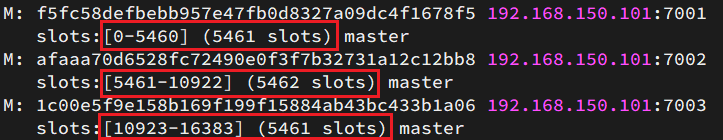

原图的槽范围均包含两端：0—5460 有 5461 个，5461—10922 有 5462 个，10923—16383 有 5461 个，总计 16384。槽可迁移到其他主节点，key 的槽计算规则保持不变；扩容需要实际迁移数据，并非多启动一个节点就自动完成。

hash tag 是 key 中控制参与计算的片段：

| key | 实际参与 CRC16 的内容 |
| --- | --- |
| `num` | `num` |
| `{itcast}num` | `itcast` |
| `user:{1001}:info`、`user:{1001}:orders` | 都是 `1001`，因此同槽 |
| `foo{}{bar}` | 整个 key，第一对括号为空 |
| `foo{{bar}}zap` | `{bar` |
| `foo{bar}{zap}` | `bar` |

补充/校正：找**第一个 `{` 及其右边第一个 `}`**；中间非空才按片段计算，否则按整个 key，不跳过空括号继续找后面的标签。把整个业务都放进相同标签，会让数据集中到一个槽，形成容量与流量热点。


## 14. MOVED、ASK 与跨槽限制

连接任意节点不等于该节点会代理所有命令。Cluster 客户端通常维护“槽 → 节点”映射，路由出错或迁移时根据服务端响应重新发请求。（课件第 25、27 页；补充/校正）

| 响应 | 场景 | 客户端行为 |
| --- | --- | --- |
| `MOVED` | 该槽由其他节点负责 | 到目标节点重发，更新/刷新槽映射 |
| `ASK` | 槽正在迁移，本次请求需到迁入节点 | 在目标连接发送 `ASKING` 再重发本次请求，暂不永久改槽映射 |
| `CROSSSLOT` | 需要同槽的多 key 操作涉及不同槽 | 调整 key 设计，或由业务拆分操作 |
| `TRYAGAIN`（补充） | 同槽多 key 在迁移中暂时分散等情况 | 有界重试，处理暂时不可执行 |

因此课件“转发到正确节点”应理解为**客户端处理重定向**，而不是 Redis 节点自动代理转发。

学习命令示例，前提是已搭建真实 Cluster：

```bash
redis-cli -h 192.168.150.101 -p 7001 CLUSTER INFO
redis-cli -h 192.168.150.101 -p 7001 CLUSTER KEYSLOT "user:{1001}:info"
redis-cli -h 192.168.150.101 -p 7001 CLUSTER KEYSLOT "user:{1001}:orders"
redis-cli -c -h 192.168.150.101 -p 7001 GET "user:{1001}:info"
```

`redis-cli -c` 可处理 Cluster 重定向。通常多 key 命令、事务与 Lua 脚本操作的 key 必须同槽，即使不同槽当前恰好位于同一主节点也不能据此绕过限制；客户端分拆后的多个操作不具有原命令的整体原子性。Cluster 仅支持 **DB 0**，不能沿用单机的 `SELECT` 多数据库隔离方式。


## 15. redisObject：类型与编码为什么要分开

业务看到的是 String、Hash、ZSet 等类型，Redis 还要根据数据规模选择更省内存或更快的表示。`redisObject`（常简称 `robj`）把类型、编码与实际数据关联起来。（课件第 31 页）

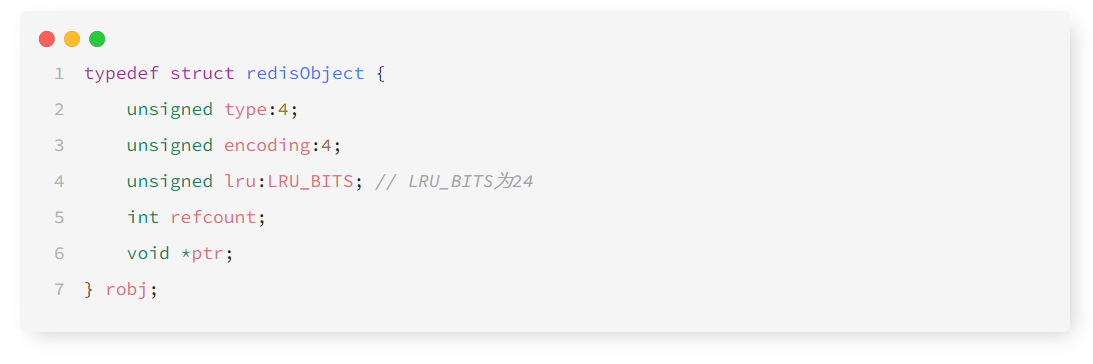

| 字段 | 课件所示职责 |
| --- | --- |
| `type:4` | 对外的数据类型，如 `OBJ_STRING`、`OBJ_ZSET` |
| `encoding:4` | 内部表示，如 `INT`、`RAW`、`SKIPLIST` |
| `lru:24` | 按淘汰策略记录 LRU 时间或 LFU 信息 |
| `refcount` | 引用计数，配合对象生命周期管理 |
| `ptr` | 指向实际数据 |

`type` 回答“能用哪些命令”，`encoding` 回答“内部怎样存”。同样是 String，可以用整数表示，也可以用动态字符串；编码转换一般不改变业务类型。

> 补充/校正：不能笼统说“数据库的 key、value 都是同样的 robj”。以本篇说明基线为例，数据库主字典的 key 通常是 SDS，value 使用 robj；SDS 是带长度等信息、支持二进制内容的动态字符串。结构布局和内部编码随版本演进，不能把课件截图当作所有版本的固定 ABI。


## 16. 课件的 12 种编码与五种常见类型

“Redis 有五种数据类型”和“底层有多种编码”不是矛盾：一类业务数据可能有多种内部实现。（课件第 32—33 页）

| 课件编码 | 含义/定位 |
| --- | --- |
| `raw` | SDS 动态字符串 |
| `int` | String 的整数表示 |
| `ht` | 哈希表/字典，便于按键定位 |
| `zipmap` | 历史紧凑映射，已退出这些常见类型的主流实现 |
| `linkedlist` | 历史双端链表 |
| `ziplist` | 历史压缩列表，连续紧凑存储 |
| `intset` | 整数集合，适合较小的纯整数 Set |
| `skiplist` | 跳表，支持有序检索 |
| `embstr` | 小字符串的对象与字符串一次分配，降低分配开销 |
| `quicklist` | 链表连接多个紧凑块，服务于 List |
| `stream` | Stream 数据的编码 |
| `listpack` | 紧凑连续存储结构，在新实现中替代部分 ziplist |

| 常见类型 | 课程涉及的内部表示 | 判断重点 |
| --- | --- | --- |
| String | `int / embstr / raw` | 可解析整数、小字符串、普通字符串 |
| List | 早期 `linkedlist / ziplist`；3.2 起 `quicklist` | quicklist 是链式结构加紧凑块；块的表示也有版本变化 |
| Set | `intset / ht` | 元素是否全为整数、规模是否超过阈值 |
| ZSet | 小集合 `ziplist` 或 Redis 7.0 起 `listpack`；较大时 `dict + skiplist` | 数量与元素大小影响编码 |
| Hash | 小对象 `ziplist` 或 Redis 7.0 起 `listpack`；较大时 `ht` | 字段数、字段/值长度影响编码 |

这是课程的历史编码清单，不意味着当前所有版本恰好只有 12 种编码，也不意味着 Redis 只有五种类型；Stream 已在编码表中出现。

补充学习命令：

```redis
SET demo:count 100
SET demo:name jack
TYPE demo:count
OBJECT ENCODING demo:count
OBJECT ENCODING demo:name
```

`TYPE` 返回业务类型，`OBJECT ENCODING` 返回当前编码。不要把某个长度阈值硬记成永久规则，应该结合 Redis 版本和紧凑结构配置判断；数据变大、内容变化后，编码也可能转换。


## 17. SkipList：跳过很多节点还能知道排名

有序链表查找较远位置要逐个走，跳表在有序链表上增加随机的多层“捷径”，先大步前进，再下层精确定位。（课件第 35—36 页）

```text
高层：头 ─────────→ 10 ─────────→ 20
中层：头 ───→ 5 ──→ 10 ───→ 15 ──→ 20
底层：头 → 1 → 2 → 3 → …… → 20
                         ↑
                查找时由高层逐步下降
```

示意图表达“越高越稀疏”，实际层高随机，层间距不固定。Redis 相关实现的节点层高最多为 32；随机层高避免维护严格平衡树的复杂调整。

| 机制 | 用途 |
| --- | --- |
| `forward` | 各层向前跳跃，按顺序寻找目标 |
| `span` | 记录跨过的底层元素数，累加后计算排名 |
| `backward` | 底层反向遍历，服务于倒序查询 |
| 多层指针 | 用额外空间换取平均更快的查找 |

补充/校正：底层有反向指针，不代表所有层都是双向链表。跳表查找、插入、删除通常为**期望 O(log N)**，最坏可退化为 O(N)；有序范围查询通常为 O(log N + M)，M 是返回元素数。

它与平衡树都能服务有序查询，不能笼统说跳表在所有情况下更快或空间必然更大；Redis 的选择还考虑实现复杂度、范围扫描、排名和指针开销。


## 18. SortedSet 为什么组合字典与跳表

排行榜既要快速查“某用户的分数”，又要查“前十名/某个分数区间”。较大的 SortedSet 同时维护字典与跳表，让两种访问各用所长。（课件第 38—39 页）

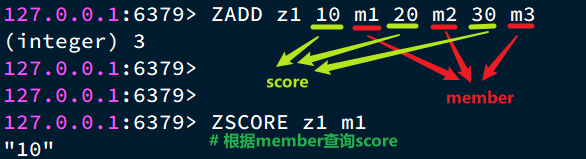

| 结构 | 组织方式 | 擅长的查询 |
| --- | --- | --- |
| 字典 `dict` | `member → score` | `ZSCORE`，按成员查分数，平均 O(1) |
| 跳表 `skiplist` | 按 score，再按 member 排序 | 排名、分数区间、有序范围，常见 O(log N) 或 O(log N + M) |

`member` 唯一，`score` 可以重复。重复写同一个 member 会更新分数；分数相同时按 member 的字节序排序，不能默认按加入先后排序。

```redis
ZADD z1 10 m1 20 m2 30 m3
ZSCORE z1 m1
ZRANK z1 m2
ZRANGE z1 0 1 WITHSCORES
ZADD z1 25 m2
ZRANGE z1 0 -1 WITHSCORES
```

示例中 `m2` 原排名为 1（从 0 开始）；改成 25 分仍只有一个 `m2`，最终分数顺序为 `m1=10、m2=25、m3=30`。这些是命令语义说明，非本篇实际运行输出。

> 补充/校正：不是所有 ZSet 永远同时具有 dict 和 skiplist。小集合可使用紧凑编码；满足数量/大小等转换条件后才切换到字典加跳表。紧凑表示省内存，查找方式与复杂度也不同。


## 19. TTL 与 expires：到期时间记录在哪里

缓存要限制旧数据寿命，Redis 通过 TTL（Time To Live，存活时间）设置整个 key 的有效期。（课件第 42—44 页）

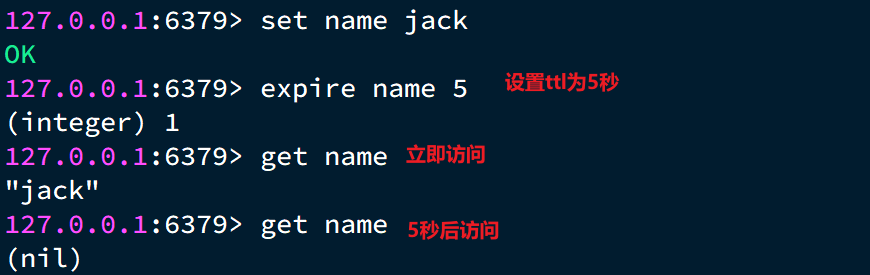

课件对应的 `redisDb` 包含两个字典：`dict` 保存数据，`expires` 保存设置了过期时间的 key 及其**绝对到期时间**。一个 key 没有 TTL，就不会因为“长期没访问”自动到期；内存淘汰另有条件。

```redis
SET name jack
EXPIRE name 5
TTL name
PTTL name
SET cache:product:1001 "{\"id\":1001,\"name\":\"茶\"}" EX 300
```

`EXPIRE` 的单位是秒，`PTTL` 查询剩余毫秒。`TTL` 返回 -1 表示 key 存在但没有过期时间，-2 表示 key 不存在。数据与 TTL 分两条命令设置时，中间故障可能留下无 TTL 的 key；缓存通常用 `SET … EX/PX` 一次完成。

补充：普通 `SET` 覆盖已有值时默认会清除原 TTL，除非使用对应保留/重设选项。需要分清**逻辑上已经到期、访问时视为不存在**与**物理内存已经释放**；它们未必发生在同一瞬间。


## 20. 惰性清理与主动清理怎样配合

为每个 key 设置精确删除定时器会带来巨大调度成本；只在访问时删除又会让无人访问的过期 key 占内存。Redis 将两种方法结合。（课件第 45—46 页）

| 方法 | 触发方式 | 权衡 |
| --- | --- | --- |
| 惰性清理 | 操作 key 时检查是否到期 | 避免为未访问的 key 单独调度，但冷 key 可能滞留 |
| 主动清理（课件称周期删除） | 定期检查部分带 TTL 的 key，并按预算继续清理 | 控制额外 CPU，逐步回收冷的过期 key |

主动清理不是每轮扫描全部 key；采样/遍历到的过期比例与时间预算会影响本轮工作量。以 Redis 7.0.15 默认努力级别说明课件数字：

| 模式 | 默认基线 | 解释 |
| --- | --- | --- |
| SLOW | `hz=10` 时每秒约 10 次，单次预算约 25 ms | 默认最多使用对应周期约 25% 的时间 |
| FAST | 基线预算约 1 ms，相邻启动至少约 2 ms | 在事件循环相关路径中按条件补充工作 |

补充/校正：`hz`、`dynamic-hz`、`active-expire-effort` 和版本会改变频率/预算，源码也按阶段检查耗时；上表不是所有请求环境下的硬实时上限。FAST 不保证每轮循环都执行。

到期后访问正常应视为未命中，但未访问的过期对象可能尚未清理。启用相应 lazyfree 选项时，大对象内存还可后台释放；逻辑删除、过期统计与 RSS（进程驻留物理内存）变化要分别观察。


## 21. 过期与内存淘汰：两套不同的判断

key 没到期，也可能在内存不足时被删除；key 已到期，也无需等到内存满再清理。**过期按时间，淘汰按内存压力与策略**。（课件第 48 页）

通过 `maxmemory` 设置淘汰判断使用的内存阈值，通过 `maxmemory-policy` 选择策略。下表整理课件的八种策略，不将“八种”当作所有后续版本的固定总数。

| 策略 | 候选范围 | 选择方式 |
| --- | --- | --- |
| `noeviction` | 不选 key | 不淘汰；内存不足时拒绝部分需要更多内存的命令 |
| `volatile-ttl` | 带 TTL 的 key | 优先剩余 TTL 较短者 |
| `volatile-random` | 带 TTL 的 key | 随机 |
| `allkeys-random` | 全部 key | 随机 |
| `volatile-lru` | 带 TTL 的 key | 近似最近最少使用 |
| `allkeys-lru` | 全部 key | 近似最近最少使用 |
| `volatile-lfu` | 带 TTL 的 key | 近似最少频率使用 |
| `allkeys-lfu` | 全部 key | 近似最少频率使用 |

补充：`volatile-*` 没有合适的 TTL 候选时可能无法回收到所需内存，转而拒绝相关写入；`noeviction` 不意味着读取和所有写命令都被禁止，释放空间的操作仍有意义。实际默认策略应以部署配置为准，不能只记课件默认值。

纯缓存可从 `allkeys-lru` 或 `allkeys-lfu` 结合流量评估；锁、业务关键状态等不能承受随机丢失的数据，应考虑与可随时回源的缓存隔离。**不被淘汰仍不等于故障时不丢失**。


## 22. LRU 与 LFU：最近使用还是长期频率

一次临时访问会让 LRU 认为一个旧 key 很“新”；LFU 还要判断它是否持续被频繁访问。（课件第 48—49 页）

| 维度 | LRU | LFU |
| --- | --- | --- |
| 全称 | Least Recently Used | Least Frequently Used |
| 关注 | 距离最近访问的时间 | 估计访问频率，结合时间衰减 |
| 倾向 | 保留最近访问的对象 | 保留持续频繁访问的对象 |
| Redis 实现 | 抽样与候选池，近似排序 | 抽样、概率计数、衰减，近似频率 |

课件对象中的 24 位 `lru` 被复用：LRU 下是秒级的低精度时间信息；LFU 下高 16 位记录分钟级时间基准，低 8 位是最多 255 的逻辑计数。**255 不是只允许访问 255 次**。

补充/校正：LFU 不会每访问一次必加 1。以 Redis 7.0.15 的 `LFULogIncr` 说明：

```text
base = max(counter - LFU_INIT_VAL, 0)
P = 1 / (base × lfu_log_factor + 1)
若随机数 R < P，则 counter + 1；255 时不再增长
```

`LFU_INIT_VAL` 是新对象的初始计数基线。课件简化公式省略了这一基线；重点记住“计数越高，继续增长的概率越低”。`lfu-log-factor` 常见默认值为 10，`lfu-decay-time` 常见默认为 1 分钟。

衰减在访问/评估候选等路径按已过去的周期计算，不是每分钟定时遍历所有 key 去减 1。时间衰减让曾经很热的对象逐渐变冷；`maxmemory-samples` 增大通常能改善近似选择，也会多消耗 CPU。策略优劣要用命中率与业务流量验证。


## 23. maxmemory 为什么不是 RSS 的硬上限

把 `maxmemory` 设到机器全部内存，仍可能使进程被系统终止。Redis 的淘汰计量与操作系统看到的物理内存不是同一个口径。（补充，结合课件第 13、48 页）

| 内存/指标 | 用途 |
| --- | --- |
| 数据与对象开销 | 业务数据实际占用，需要控制大 key 和数量 |
| `mem_not_counted_for_evict` | 部分复制/AOF 等缓冲不计入淘汰判断 |
| `used_memory_rss` | 操作系统视角的进程驻留内存 |
| 碎片、fork 写时复制 | 可能使物理占用与瞬时峰值额外增加 |

补充配置示例，仅表示选择思路，不是课程文件原文：

```conf
maxmemory 512mb
maxmemory-policy allkeys-lfu
maxmemory-samples 5
```

```redis
INFO memory
INFO stats
MEMORY USAGE cache:product:1001
```

结合 `used_memory`、`used_memory_rss`、`mem_not_counted_for_evict`、`evicted_keys`、`expired_keys` 判断压力来自数据、淘汰、过期还是额外开销。可用 `keyspace_hits / (keyspace_hits + keyspace_misses)` 估计 Redis keyspace 命中率，分母为 0 时不计算；业务缓存命中率还应单独统计，因为业务“负缓存命中”等口径可能不同。

`maxmemory=0` 通常表示不由该参数限制数据内存，不代表内存无限。容量规划要为系统、缓冲、碎片和持久化峰值留余量；Cluster 中按每个实例设置与观察，而不是只看集群总和。


## 24. 淘汰、TTL 与主动失效怎样组合

缓存是数据库数据的副本，更新数据库后，原缓存不会自然知道新值。三种维护机制在成本和新鲜度上不同。（课件第 52、58 页）

| 方式 | 更新/失效触发 | 新鲜度边界 |
| --- | --- | --- |
| 内存淘汰 | 内存不足才挑选 key 删除 | 无法保证某条旧数据什么时候被刷新 |
| TTL 到期 | 给 key 设置期限，到期后再回填 | 允许一段旧值窗口，回填竞争也需处理 |
| 主动失效/更新 | 数据变化时删除或更新相关缓存 | 可缩短窗口，但失败、提交顺序与并发仍需处理 |

课件将分类等低一致性数据与内存淘汰关联。补充/校正：**即使允许数据稍旧，也应明确 TTL 或主动失效路径**，不能把淘汰当成确定的刷新计划；内存充足时旧值可能一直保留。

常见组合是“数据库提交后删除缓存 + 回填时设置 TTL”。TTL 用作漏失效的兜底，同时还要确保回填 TTL 确实写入；能接受多久的旧值由业务要求决定，不应对所有数据套同一个时间。


## 25. 三种缓存模式谁来维护数据

维护职责不同，会直接影响失败重试和一致性设计。（课件第 53 页）

| 模式 | 读路径 | 写路径/职责 | 主要边界 |
| --- | --- | --- | --- |
| Cache Aside | 应用查缓存，miss 后查库并回填 | 应用写库后使缓存失效 | 应用自己处理两套系统的失败与竞争 |
| Read/Write Through | 通过统一服务/缓存层访问，miss 由该层查库 | 统一层同步处理持久化与缓存 | 封装职责不自动创造跨系统原子性 |
| Write Behind | 多数请求先与缓存层交互 | 先接受缓存写入，再异步持久化 | 顺序、积压、丢失、重放与持久化失败风险 |

本课主要采用 **Cache Aside（旁路缓存）**。Redis 本身不会因写入某个 key 就自动写 MySQL；Read/Write Through 需要相应服务/组件实现，Write Behind 还需要可靠队列、持久化与重试设计。

关键业务数据不能仅因为“异步最终写库吞吐高”就选择 Write Behind，要先确定系统故障时是否允许丢写、能否保序，以及重复事件怎样处理。


## 26. Cache Aside：读时回填，写时失效

不是每次数据库修改都值得立刻计算一份缓存；删除缓存可以让真正需要它的查询再做重建。（课件第 54、58 页）

```text
读：
  检查参数与权限 → GET 缓存
  命中正常数据 → 返回
  命中 NOT_FOUND 哨兵 → 返回不存在
  未命中 → 查数据库
      存在 → 写缓存并设置 TTL → 返回
      明确不存在 → 按业务策略写短 TTL 负缓存 → 返回
      数据库异常 → 走失败/降级路径，不能伪装成不存在

写：
  在数据库事务中更新数据
  数据库提交成功
      ↓
  删除相关缓存；失败则进入可靠重试/补偿
```

更新缓存也可以采用，但并发更新可能让旧写覆盖新写，且对无人读取的数据做了额外缓存写入。删除操作更容易做到幂等：重复删除已不存在的 key，不会累积业务副作用。

补充：失效范围不一定只有一个商品详情 key。详情、列表、聚合、负缓存等都可能依赖同一条数据，需维护明确的依赖规则；扩大删除范围会增加回源成本，漏删则留下旧值。


## 27. 两种操作顺序为什么都可能出现旧值

“先写数据库，再删除缓存”更常用，但它不是消除所有竞争的证明。用数据库旧值 10、新值 20 看两个时序。（课件第 55—57 页）

**先删缓存，再写数据库：**

| 时刻 | 写线程 W | 读线程 R |
| --- | --- | --- |
| 1 | 删除缓存 | |
| 2 | | miss，读数据库旧值 10 |
| 3 | | 回填缓存 10 |
| 4 | 数据库提交新值 20 | |

结果是数据库 20，缓存 10。删除太早，给旧值重新进入缓存留下了直接窗口。

**先提交数据库，再删缓存：仍有旧读晚回填：**

| 时刻 | 读线程 R | 写线程 W |
| --- | --- | --- |
| 1 | 原先 miss，读数据库旧值 10，随后停顿 | |
| 2 | | 数据库提交新值 20 |
| 3 | | 删除缓存 |
| 4 | 恢复运行，回填缓存 10 | |

补充判断：提交后删除缩小了常见竞争窗口，但旧查询的长延迟、慢计算、数据库副本延迟仍可能让旧值晚回填。删除后立刻查询如果又从落后的数据库副本取值，也可能重新缓存旧值。

`TTL` 可以让这次错误回填随后失效；要求更严格时，要设计版本校验、读写协调或直接读权威数据源。不能只依赖“这个时序发生概率低”就声称强一致。


## 28. 数据库事务与缓存失效怎样可靠衔接

数据库提交成功，Redis 删除失败，是两个系统独立失败的常见情况。反过来，在数据库提交前删除，即使删除成功，也可能被并发读回填旧值。（课件第 54、58 页；补充/校正）

> 课件“单体把数据库和缓存放进一个事务”不能直接理解为普通 `@Transactional` 自动让 MySQL 与 Redis 原子提交。MySQL 本地事务与 Redis `MULTI/EXEC` 各有自己的作用域；单体部署不改变它们是两个资源的事实。

| 手段 | 解决的问题 | 边界 |
| --- | --- | --- |
| 数据库提交后回调删除 | 避免提交前过早失效 | 进程在提交后、执行回调前退出，仍会漏删 |
| 可靠重试/补偿 | 删除异常后继续处理 | 需要持久记录、幂等、退避、告警 |
| 事务发件箱 + MQ | 在数据库事务中同时记录“需失效事件”，提交后异步投递 | 投递/消费仍需重试；有最终一致窗口 |
| CDC | 订阅数据库变更日志，再失效缓存 | 要处理日志位点、延迟、恢复和所有写入口 |
| TTL | 兜住部分漏失效 | 不是立即一致，也不能替代可靠事件 |

事务发件箱（Outbox）是把业务修改与待发送事件写入**同一个数据库事务**；后台再投递事件，消费者删除缓存。真正原子的是数据库内这两次写入，不是同时跨 MySQL、Redis、MQ 提交。

延迟双删是在稍后再删一次以覆盖部分晚回填。补充：固定休眠不能覆盖所有慢请求，进程故障也可能让第二次删除丢失；可作补偿措施，不能作为严格一致证明。分布式事务/TCC 也需明确参与者、隔离、补偿与成本，并不是给调用加个名称就生效。


## 29. 缓存穿透与负缓存

缓存穿透是**请求的数据在缓存与数据库都不存在**，导致每次 miss 都打到数据库。例如不断查询不存在的商品 ID。（课件第 60、63 页）

先做格式、范围、权限与限流检查，再考虑缓存不存在的结果。负缓存用明确哨兵表示“已经查过，确实不存在”，不能和“Redis 没有这个 key”混为一谈。

```redis
SET cache:product:999999 "{\"kind\":\"NOT_FOUND\"}" EX 60
```

这里的 60 秒是补充示例，不是固定最佳值。正常数据可采用带 `kind=DATA` 与 `payload` 的协议，以避免有效业务值与哨兵冲突。

| 处理 | 原因 |
| --- | --- |
| 设置短 TTL | 避免“不存在”状态长期挡住后来创建的数据 |
| 新建数据提交后删除负缓存 | 减少创建成功仍查询不到的窗口 |
| 不把超时/数据库异常写成 NOT_FOUND | 查询失败不代表数据不存在 |
| 限制负缓存数量与请求速率 | 随机 ID 攻击可能产生大量不同 key |

缓存空对象实现简单、对重复不存在 ID 有效，但会耗内存并产生短暂不一致；对无穷变化的非法 ID，只加空值缓存仍不够。


## 30. 布隆过滤器为什么会误判

存储海量 ID 的完整集合成本较高，布隆过滤器用位数组与多个哈希映射，先筛掉肯定不在集合中的请求。（课件第 60—62 页）

```text
添加 ID：
  多个哈希函数 → 多个位位置 → 全部置 1

查询 ID：
  任一对应位是 0 → 判定不在已录入集合
  对应位全是 1 → 可能存在，继续查缓存/数据库
```

不同 ID 可能共享位。一个从未加入的 ID 所对应的位，可能已被其他 ID 全部置为 1，这就是**假阳性（误判为可能存在）**。过滤器返回“可能存在”不是数据存在的证明。

| 性质 | 使用前提/含义 |
| --- | --- |
| 判不存在可以直接拦截 | 前提是所有允许访问的 ID 已完整录入，更新链路正确 |
| 判可能存在仍需查询 | 会出现假阳性 |
| 标准布隆不能简单清位删除 | 清除共享位可能让其他元素被误判不存在 |
| 容量与误判率要规划 | 录入过多元素会使更多位为 1，过滤效果下降 |

补充/校正：“没有假阴性”针对正确维护的已插入集合；**新建 ID 没同步到过滤器**时，业务仍可能被误拒。因此要设计初始化、增量更新、异常时策略和重建/切换流程，删除可采用定期重建或适合删除的结构。

Redis 位操作可作为实现材料；`BF.ADD/BF.EXISTS` 是否可用要看部署的产品、版本或模块。不能仅因为使用 Redis 就认定现成布隆命令已经具备。


## 31. 缓存雪崩：批量失效与服务不可用

雪崩是同一时段**大量不同 key** 失效，或整个 Redis 服务不可用，大量请求集中回源到数据库。（课件第 65 页）

| 原因 | 对应措施 |
| --- | --- |
| 批量写入了相同过期时间 | TTL 加随机抖动，错开到期与预热批次 |
| Redis 节点/服务不可用 | Sentinel/Cluster、正确的客户端切换与超时 |
| 回源流量超过数据库能力 | 限流、熔断、降级、并发回源上限 |
| 热点集中依赖远端缓存 | 合理的本地缓存/多级缓存、预热 |

补充 TTL 示例：`ttl = 300 秒 + [0, 60] 秒随机值`，使批量数据不集中在同一秒到期。随机范围应符合数据新鲜度要求；它能缓解批量到期，**不能修复 Redis 整体宕机**。

```text
Redis 故障
   ↓
短超时 + 有界重试
   ↓
本地旧缓存/降级结果（业务允许时）
   ↓
有限并发回源数据库；超出额度时拒绝或降级
```

补充：多级缓存可减轻远端故障冲击，也引入各进程缓存的失效与一致性问题。异常后让每个请求无条件直查数据库，会把缓存故障扩大成数据库故障；高可用切换过程中仍需要回源保护。


## 32. 缓存击穿为什么需要合并重建

击穿集中在**一个或少量高并发热点 key**：它到期时，很多请求同时 miss，昂贵的数据库查询或聚合被重复执行。（课件第 67 页）

```text
同一个热点 key 到期
   ↓
1000 个请求同时 miss
   ↓ 不做协调
1000 次回源 + 重复计算 + 争相回填
```

目标是将同一 key 的并发 miss 合并为少数重建任务。互斥重建让其他请求有限等待/重试；逻辑过期则允许先返回旧值，由少数任务异步更新。

补充：本地 single-flight（同一进程内合并相同请求）只能约束一个应用实例。多实例可能仍各回源一次；需要结合数据库承载能力判断是否使用跨实例协调。不同 key 的雪崩，不能仅用“一把热点 key 锁”解决。


## 33. 互斥重建：拿到锁后为什么还要再查一次

只让拿到锁的线程查库，可以削减瞬时回源。但等待期间另一个线程可能已经写好缓存，因此持锁后应**二次检查缓存**。（课件第 68 页；补充流程）

```text
读取缓存
  ├─ 命中：返回
  └─ miss：尝试获取该 key 的重建锁
       ├─ 失败：短暂退避后再查缓存；超过等待预算则降级/报错
       └─ 成功：
            再查一次缓存
              ├─ 已有值：直接使用
              └─ 仍 miss：查数据库 → 写数据/负缓存并设置 TTL
            finally 按持有者令牌释放锁
```

| 必须判断 | 原因 |
| --- | --- |
| 每个 key 有自己的锁 | 不把所有商品查询串行化 |
| 获取锁同时设置租约 | 防止线程退出后锁永不释放 |
| 有界等待与重试 | 避免递归重试、线程长期占用、重试风暴 |
| 重建异常及时结束 | 不能无限循环重试，也不能缓存数据库错误为空值 |
| 租约与重建耗时匹配 | 锁先到期时，可能出现多个重建者 |

> 补充/校正：互斥锁主要减少重复重建；它不自动保证数据库与缓存强一致。业务写线程不遵循同一协调协议、旧值晚回填、锁租约过期或故障切换，都可能突破所设想的串行边界。


## 34. Redis 重建锁的令牌、租约与释放

“先 SETNX 再 EXPIRE”之间存在故障窗口；“直接 DEL 锁”还可能误删别人后来获得的锁。获取应在一条命令中完成，释放应原子比较持有者令牌。（补充，结合课件第 68—69 页）

```redis
SET lock:product:{1001} "request-token-A" NX PX 10000
```

`NX` 表示仅在 key 不存在时设置，`PX 10000` 表示 10 秒租约。令牌应每次获取重新生成且唯一；上面的固定字符串仅用于讲解。返回 `OK` 才算获取成功，未获取到不能执行释放逻辑。

释放 Lua 示例，`KEYS[1]` 为锁 key，`ARGV[1]` 为本次令牌：

```lua
if redis.call('get', KEYS[1]) == ARGV[1] then
    return redis.call('del', KEYS[1])
end
return 0
```

Lua 在单个 Redis 节点内原子执行比较与删除；不能在应用中分成 GET、判断、DEL 三次操作。

```text
A 获得锁 → A 停顿，租约到期
B 获得同一个锁，保存 B 的令牌
A 恢复并释放
  直接 DEL：可能删除 B 的锁
  比较 A 的令牌再删：不匹配，不删除
```

补充：令牌比较只防止误释放，不能阻止超时后的 A 继续进行旧的回填。必要时续租也要检查持有者，并考虑失效后的写入约束。锁被内存淘汰或 Redis 主从切换丢失，同样可能让第二个线程拿到锁；不得据此推导关键业务写操作绝对互斥。本节是缓存重建示例，不代替完整分布式锁设计。


## 35. 逻辑过期：为什么能返回旧值

允许短暂旧数据的热点查询，可以把“什么时候应刷新”存进缓存内容；数据仍在 Redis 中，到逻辑期限后先返回旧值，再触发异步重建。（课件第 68 页）

补充协议示例，其中 `expireAtEpochMs` 是业务记录的逻辑到期毫秒时间戳：

```json
{
  "data": {"id": 1001, "name": "茶", "price": 1200},
  "expireAtEpochMs": 2000000000000
}
```

这里 `price` 仅为示例整数分，时间也是占位示例值。逻辑到期由应用比较当前时间；它和 Redis 的物理 TTL 是两个字段/机制。

```text
缓存存在且未逻辑过期 → 返回数据
缓存存在但逻辑过期
  ├─ 未获重建锁：返回旧数据
  └─ 获得锁：安排异步重建，当前请求先返回旧数据
             工作线程二次检查 → 查库 → 写新值与新逻辑期限
             finally 令牌校验后释放锁
缓存真正不存在/已被淘汰 → 走普通 miss 与受保护的重建路径
```

补充实践：预热关键热点，使用**有界线程池与任务队列**，合并重复任务；提交任务失败或任务异常时都要处理锁和重试。可以设置更长物理 TTL 作容量/安全兜底，但物理到期后已无旧值可返回，不能把它继续当逻辑过期命中。

长期重建失败可能让旧值持续返回，要规定最大可接受陈旧时间、告警与超限降级。逻辑过期换取的是较短请求等待，适合允许短暂陈旧的展示数据。


## 36. 穿透、雪崩、击穿如何快速区分

问题名相似，解决手段却针对不同的流量来源。（课件第 60—69 页）

| 问题 | 数据/流量特征 | 首要处理 |
| --- | --- | --- |
| 穿透 | 请求数据库根本没有的数据 | 校验、权限、限流、短 TTL 负缓存、布隆过滤 |
| 雪崩 | 大量不同 key 同时失效，或 Redis 服务不可用 | TTL 抖动、高可用、回源限流、多级缓存与降级 |
| 击穿 | 少数热点 key 失效，很多请求同时重建 | 合并回源、互斥重建、逻辑过期 |

| 击穿方案 | 请求体验 | 新鲜度/维护成本 |
| --- | --- | --- |
| 互斥重建 | 一部分线程要有限等待，重建失败需降级 | 可减少并发回源；还需处理写入竞争与锁边界 |
| 逻辑过期 | 通常快速返回已有旧值 | 显式允许陈旧；增加时间字段、预热、异步任务管理 |

课件将互斥锁概括为“保证一致性”、将逻辑过期概括为“不保证一致性”。更准确的说法是：**前者协调并发重建，后者允许旧值服务；完整的一致性仍取决于读写、提交、失效和失败处理协议**。

一个接口可能同时遇到三类问题，应组合保护手段。例如商品详情采用参数检查 + 负缓存 + TTL 抖动 + 热点重建合并 + 数据库提交后失效，而不是只能任选一个方案。


## 37. 怎样验证这些方案有效

配置能启动，不能证明切换、数据边界和流量保护都正确。以下是学习环境中的验证矩阵，本篇只整理方法，**未执行服务实验**。

| 验证目标 | 方法 | 观察证据 |
| --- | --- | --- |
| 主从复制 | 写主、读副本，查看 `INFO replication` | 角色、连接状态、复制 offset 与延迟 |
| 部分/全量同步 | 短断连与超出 backlog 的断连分别恢复 | 日志、`sync_partial_ok / sync_partial_err / sync_full` 的变化 |
| Sentinel 切换 | 让示例主节点不可用，客户端重新发现 | 当前主地址、角色变化、恢复耗时与失败请求 |
| quorum/授权 | 分别构造满足 quorum、缺少多数的场景 | ODOWN 与实际切换是否分离 |
| Cluster 路由 | 比较有相同 tag 的 key，访问非属主节点 | `CLUSTER KEYSLOT`、`MOVED/ASK` 与客户端重发 |
| TTL 与内存 | 观察 key 到期、统计与 RSS | 逻辑 miss、`expired_keys`、物理内存变化 |
| 淘汰 | 在受限内存的独立示例环境写入可丢弃缓存 | `evicted_keys`、拒绝命令与命中率 |
| 写后失效 | 模拟提交后删除失败、进程退出、重复消息 | 持久事件、幂等重试、告警与最终回源 |
| 并发回填 | 控制旧查询暂停，再提交新值并删除 | 能否出现旧值晚回填，TTL/版本协议如何处理 |
| 击穿保护 | 热点缓存失效时并发请求 | 数据库回源次数、等待上限、线程池积压与错误率 |
| 逻辑过期 | 同时构造陈旧命中、真实 miss、重建失败 | 是否按约定返回旧值、保护回源、处理锁与任务 |

补充：不要把“副本 offset 最终追上”“执行过 DEL”“拿到了重建锁”分别当成整体强一致证明。验证应覆盖故障和竞争时序，并以业务能接受的陈旧时间、失败率、数据库负载作为判断标准。


## 38. 核心回顾与面试提示

| 高频主题 | 应能说清的主线 |
| --- | --- |
| 架构选择 | 主从复制副本，Sentinel 协调主从切换，Cluster 分片容量与写入 |
| 同步 | RDB 建立全量起点，replid + offset 标识进度，backlog 支持有限历史补发 |
| 哨兵 | SDOWN → quorum 判断 ODOWN → leader 与多数授权 → 合格副本提升 |
| 分片 | 16384 槽，CRC16/hash tag，客户端处理 MOVED/ASK，多 key 同槽 |
| 底层 | 类型与编码分离；小 ZSet 紧凑表示，大 ZSet 字典加跳表 |
| 内存 | TTL 清理与内存淘汰不同；LRU 近似时间，LFU 概率计数与衰减 |
| 一致性 | 数据库提交后失效、可靠重试、TTL 兜底，仍需考虑晚回填 |
| 缓存流量 | 不存在数据是穿透，多 key/服务失效是雪崩，热点失效是击穿 |

**面试提示**：回答主从时，从 PSYNC、复制历史、快照与后续复制流讲到全量/部分同步条件，再指出异步复制的读延迟与丢写窗口。回答 Sentinel 时区分故障判断 quorum 与切换多数授权，说明副本优先级、offset、run ID 的排序。回答 ZSet 时先说 member 唯一与 score 排序，再解释字典、跳表及小集合编码。回答缓存一致性时画出“旧读 → 新值提交 → 删除 → 旧值回填”的时序，不把普通事务或重建锁说成跨系统强一致。回答穿透、雪崩、击穿时先明确流量特征，再给对应措施与失败边界。

补充核对来源（访问日期：2026-10-09）：

- [Redis replication：异步复制、复制 ID、部分同步、diskless](https://redis.io/docs/latest/operate/oss_and_stack/management/replication/)
- [Redis Sentinel：quorum、选举、副本选择、配置与客户端发现](https://redis.io/docs/latest/operate/oss_and_stack/management/sentinel/)
- [Redis Cluster specification：槽位、hash tag、MOVED/ASK、DB 0](https://redis.io/docs/latest/operate/oss_and_stack/reference/cluster-spec/)
- [Redis key eviction：maxmemory、近似 LRU/LFU、缓冲与指标](https://redis.io/docs/latest/develop/reference/eviction/)
- [Redis 7.0.15 evict.c：LFU 概率计数与衰减实现](https://github.com/redis/redis/blob/7.0.15/src/evict.c)
- [Redis 7.0.15 expire.c：SLOW/FAST 主动过期预算](https://github.com/redis/redis/blob/7.0.15/src/expire.c)
